In [1]:
using LinearAlgebra
using DifferentialEquations, Plots
using BenchmarkTools
using HypothesisTests
default(grid=false,legend=false, size=(400,320), dpi=300, tickfontsize=16, lw=2, lc=:gray, labelfontsize=16, tickdir=:out, fontfamily="Arial", legendfontsize=13, markercolor=:indianred)


mydir = "../helper/"
include(mydir * "base.jl")
include(mydir * "optimization.jl")
include(mydir * "misc.jl")

annotate_exp_traj (generic function with 2 methods)

In [2]:
using DelimitedFiles
# INSERT YOUR OWN DATA DIRECTORY AND FILENAME HERE
# E. coli MG1655 (CGSC 6300)/20090131/xy01c1/ch1_cell0.dat
data_dir = "/Users/shijiezhang/Dropbox (MIT)/stochastic_learning/complete data Curr Biol 20, 1099-1103 (2010)/E. coli MG1655 (CGSC 6300)/20090129/"
# DT = 1/60; # convert to hours
DL = 0.0645; # convert to um
DT = 0.01;

In [3]:
select_filename =[
    "xy01/ch0_cell0.dat",
    "xy01/ch1_cell0.dat",
    "xy01/ch2_cell0.dat",
    "xy01/ch3_cell0.dat",
    "xy01/ch4_cell0.dat",
    "xy01/ch5_cell0.dat",
    "xy01/ch6_cell0.dat",
    "xy01/ch7_cell0.dat",
    "xy01/ch8_cell0.dat",
    "xy01/ch9_cell0.dat",
    "xy01/ch10_cell0.dat",
    "xy02/ch0_cell0.dat",
    "xy02/ch1_cell0.dat",
    "xy02/ch2_cell0.dat",
    "xy02/ch3_cell0.dat",
    "xy02/ch4_cell0.dat",
    "xy02/ch5_cell0.dat",
    "xy02/ch6_cell0.dat",
    "xy02/ch7_cell0.dat",
    "xy02/ch8_cell0.dat",
    "xy03/ch0_cell0.dat",
    "xy03/ch1_cell0.dat",
    "xy03/ch2_cell0.dat",
    "xy03/ch3_cell0.dat",
    "xy03/ch4_cell0.dat",
    "xy03/ch5_cell0.dat",
    "xy03/ch6_cell0.dat",
    "xy03/ch7_cell0.dat",
    "xy03/ch8_cell0.dat",
    "xy03/ch9_cell0.dat",
    "xy03/ch10_cell0.dat",
    "xy04/ch0_cell0.dat",
    "xy04/ch1_cell0.dat",
    "xy04/ch2_cell0.dat",
    "xy04/ch3_cell0.dat",
    "xy04/ch4_cell0.dat",
    "xy04/ch5_cell0.dat",
    "xy04/ch6_cell0.dat",
    "xy04/ch7_cell0.dat",
    "xy04/ch8_cell0.dat",
    "xy04/ch9_cell0.dat",
    "xy05/ch0_cell0.dat",
    "xy05/ch1_cell0.dat",
    "xy05/ch2_cell0.dat",
    "xy05/ch3_cell0.dat",
    "xy05/ch4_cell0.dat",
    "xy05/ch5_cell0.dat",
    "xy05/ch6_cell0.dat",
    "xy05/ch7_cell0.dat",
    "xy05/ch8_cell0.dat",
    "xy05/ch9_cell0.dat",
    "xy05/ch10_cell0.dat",
    "xy05/ch11_cell0.dat",
    "xy05/ch12_cell0.dat",
    "xy06/ch0_cell0.dat",
    "xy06/ch1_cell0.dat",
    "xy06/ch2_cell0.dat",
    "xy06/ch3_cell0.dat",
    "xy06/ch4_cell0.dat",
    "xy06/ch5_cell0.dat",
    "xy06/ch6_cell0.dat",
    "xy06/ch7_cell0.dat",
    "xy06/ch8_cell0.dat",
    "xy06/ch9_cell0.dat",
    "xy07/ch0_cell0.dat",
    "xy07/ch1_cell0.dat",
    "xy07/ch2_cell0.dat",
    "xy07/ch3_cell0.dat",
    "xy07/ch4_cell0.dat",
    "xy07/ch5_cell0.dat",
    "xy07/ch6_cell0.dat",
    "xy07/ch7_cell0.dat",
    "xy07/ch8_cell0.dat",
    "xy07/ch10_cell0.dat",
    "xy07/ch11_cell0.dat",
    "xy08/ch0_cell0.dat",
    "xy08/ch1_cell0.dat",
    "xy08/ch3_cell0.dat",
    "xy08/ch4_cell0.dat",
    "xy08/ch5_cell0.dat",
    "xy08/ch6_cell0.dat",
    "xy08/ch7_cell0.dat",
    "xy08/ch8_cell0.dat",
    "xy08/ch9_cell0.dat",
    "xy08/ch10_cell0.dat",
    "xy09/ch0_cell0.dat",
    "xy09/ch1_cell0.dat",
    "xy09/ch2_cell0.dat",
    "xy09/ch3_cell0.dat",
    "xy09/ch4_cell0.dat",
    "xy09/ch5_cell0.dat",
    "xy09/ch6_cell0.dat",
    "xy09/ch7_cell0.dat",
    "xy09/ch8_cell0.dat",
    "xy09/ch9_cell0.dat",
    "xy09/ch10_cell0.dat",
    "xy09/ch11_cell0.dat",
    "xy10/ch0_cell0.dat",
    "xy10/ch1_cell0.dat",
    "xy10/ch2_cell0.dat",
    "xy10/ch3_cell0.dat",
    "xy10/ch4_cell0.dat",
    "xy10/ch5_cell0.dat",
    "xy10/ch6_cell0.dat",
    "xy10/ch7_cell0.dat",
    "xy10/ch8_cell0.dat",
    "xy10/ch9_cell0.dat",
    "xy10/ch10_cell0.dat",
    "xy10/ch11_cell0.dat",
    "xy10/ch12_cell0.dat",
    "xy10/ch13_cell0.dat",
    "xy11/ch0_cell0.dat",
    "xy11/ch1_cell0.dat",
    "xy11/ch2_cell0.dat",
    "xy11/ch3_cell0.dat",
    "xy11/ch4_cell0.dat",
    "xy11/ch5_cell0.dat",
    "xy11/ch6_cell0.dat",
    "xy11/ch7_cell0.dat",
    "xy11/ch8_cell0.dat",
    "xy11/ch9_cell0.dat",
    "xy11/ch10_cell0.dat",
    "xy12/ch0_cell0.dat",
    "xy12/ch1_cell0.dat",
    "xy12/ch2_cell0.dat",
    "xy12/ch3_cell0.dat",
    "xy12/ch4_cell0.dat"];

select_time_all = [
    [(0.0, 11.41), (12.31, 15.97)],
    [(0.0, 21.99)],
    [(0.0, 15.35)],
    [(0.0, 15.88), (16.32, 20.12)],
    [(0.0, 27.31)],
    [(0.0, 27.31)],
    [(0.0, 23.55)],
    [(0.0, 27.31)],
    [(0.0, 17.96), (18.64, 24.04)],
    [(0.0, 22.71)],
    [(25.78, 27.31)],
    [(0.0, 20.46)],
    [(0.0, 27.31)],
    [(0.0, 27.31)],
    [(0.0, 27.31)],
    [(0.0, 27.31)],
    [(0.0, 20.39)],
    [(0.0, 27.31)],
    [(0.0, 27.31)],
    [(10.66, 27.31)],
    [(0.0, 27.31)],
    [(0.0, 17.76)],
    [(0.0, 5.05)],
    [(0., 16.39), (17.28, 20.44)],
    [(0.0, 19.20)],
    [(0.0, 25.21)],
    [(0.0, 13.38), (17.38, 27.31)],
    [(0.0, 27.31)],
    [(0.0, 27.31)],
    [(0.0, 27.31)],
    [(8.17, 14.08)],
    [(0.0, 20.69)],
    [(0.0, 24.66)],
    [(0.0, 20.96)],
    [(0., 16.28)],
    [(0.0, 27.31)],
    [(0.0, 16.30)],
    [(0.0, 20.22)],
    [(0.0, 17.14), (17.96, 27.31)],
    [(0.0, 11.65)],
    [(0.0, 24.52)],
    [(0.0, 27.31)],
    [(0.0, 14.32)],
    [(0.0, 14.12)],
    [(0., 19.20), (20.06, 24.38)],
    [(0.0, 16.83)],
    [(3.39, 15.45)],
    [(0.0, 24.18)],
    [(0.0, 24.86)],
    [(0.0, 27.31)],
    [(0.0, 16.58)],
    [(0.0, 27.31)],
    [(0.0, 13.03)],
    [(0.0, 27.31)],
    [(0.0, 27.31)],
    [(0.0, 27.31)],
    [(0.0, 4.46)],
    [(0., 20.58)],
    [(0.0, 27.31)],
    [(0.0, 27.31)],
    [(0.0, 27.31)],
    [(0.0, 27.31)],
    [(1.31, 27.31)],
    [(11.24, 27.31)],
    [(0.0, 27.31)],
    [(0.0, 2.41), (3.19, 16.21), (17.28, 27.31)],
    [(0.0, 26.09)],
    [(0., 23.46)],
    [(0.0, 2.14)],
    [(0.0, 16.36)],
    [(0.0, 24.91)],
    [(0.0, 26.97)],
    [(1.04, 17.89)],
    [(21.36, 27.31)],
    [(22.41, 27.31)],
    [(0.0, 23.34)],
    [(0.0, 18.77)],
    [(0.0, 8.82)],
    [(0., 7.98)],
    [(0.0, 27.31)],
    [(0.0, 16.26)],
    [(0.0, 27.31)],
    [(0.0, 27.31)],
    [(0.0, 27.31)],
    [(0.0, 27.31)],
    [(0.0, 15.66)],
    [(0.0, 12.58)],
    [(0.0, 26.61)],
    [(0., 5.80)],
    [(0.0, 27.31)],
    [(0.0, 14.05)],
    [(0.0, 27.31)],
    [(0.0, 20.02)],
    [(0.0, 18.38)],
    [(0.0, 6.58)],
    [(17.89, 27.31)],
    [(20.25, 27.31)],
    [(0.0, 15.66)],
    [(0.0, 12.58)],
    [(0.0, 7.64)],
    [(0., 23.50)],
    [(0.0, 8.71), (9.08, 12.02), (12.51, 14.89)],
    [(0.0, 15.18), (15.77, 18.26)],
    [(0.0, 27.31)],
    [(0.0, 227.31)],
    [(0.0, 27.31)],
    [(0.0, 16.88)],
    [(0.0, 27.31)],
    [(7.03, 27.31)],
    [(13.83, 27.31)],
    [(21.10, 27.31)],
    [(0.90, 3.10)],
    [(0.0, 16.46)],
    [(0.0, 4.90)],
    [(0., 26.65)],
    [(0.0, 27.31)],
    [(0.0, 13.91), (15.00, 18.78)],
    [(0.0, 11.84), (12.33, 19.19)],
    [(0.0, 14.71), (16.40, 26.37)],
    [(0.0, 20.76)],
    [(0.0,27.31)],
    [(0.0, 7.19), (8.40, 16.61)],
    [(0.0, 20.96)],
    [(0.0, 2.31)],
    [(0.0, 20.06)],
    [(0., 25.57)],
    [(0.0, 11.54), (12.43, 25.71)]];

In [4]:
# annotate
Lobs_ = []
tobs_ = []
for idx in eachindex(select_filename)
    tab = readdlm(data_dir * select_filename[idx]);
    varnames = convert(Vector{String}, tab[1,:]);
    tobs = tab[2:end,findfirst(varnames .== "time")] * DT;
    Lobs = tab[2:end,findfirst(varnames .== "length")] * DL;
    Lobs_idx, tobs_idx = filter_exp_traj(Lobs, tobs; select_time = select_time_all[idx]);
    Lobs_ = vcat(Lobs_, Lobs_idx)
    tobs_ = vcat(tobs_, tobs_idx)
end
Lobs_ = convert.(Vector{Float64}, Lobs_);
tobs_ = convert.(Vector{Float64}, tobs_);

In [5]:
isdiv_, dtobs_ = annotate_exp_traj(Lobs_, tobs_);
sum(sum.(isdiv_))

11760

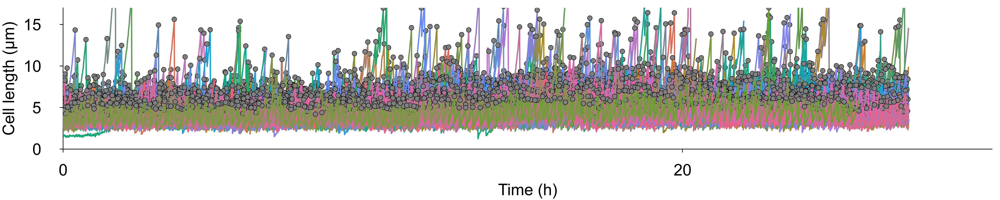

In [6]:
p_traj_obs = plot(; size=(1500,300), xlim=(0,30), ylim=(0,17), xtick=collect(0:20:80), ytick=collect(0:5:15), bottommargin=12Plots.mm,  leftmargin=9Plots.mm, xlabel="Time (h)", ylabel="Cell length (μm)")
linecolor_ = palette(:default, length(Lobs_) )
for i in eachindex(Lobs_)
    plot!(p_traj_obs, tobs_[i], Lobs_[i], lc=linecolor_[i])
    scatter!(p_traj_obs, tobs_[i][isdiv_[i]], Lobs_[i][isdiv_[i]], markercolor=:gray)
end
p_traj_obs

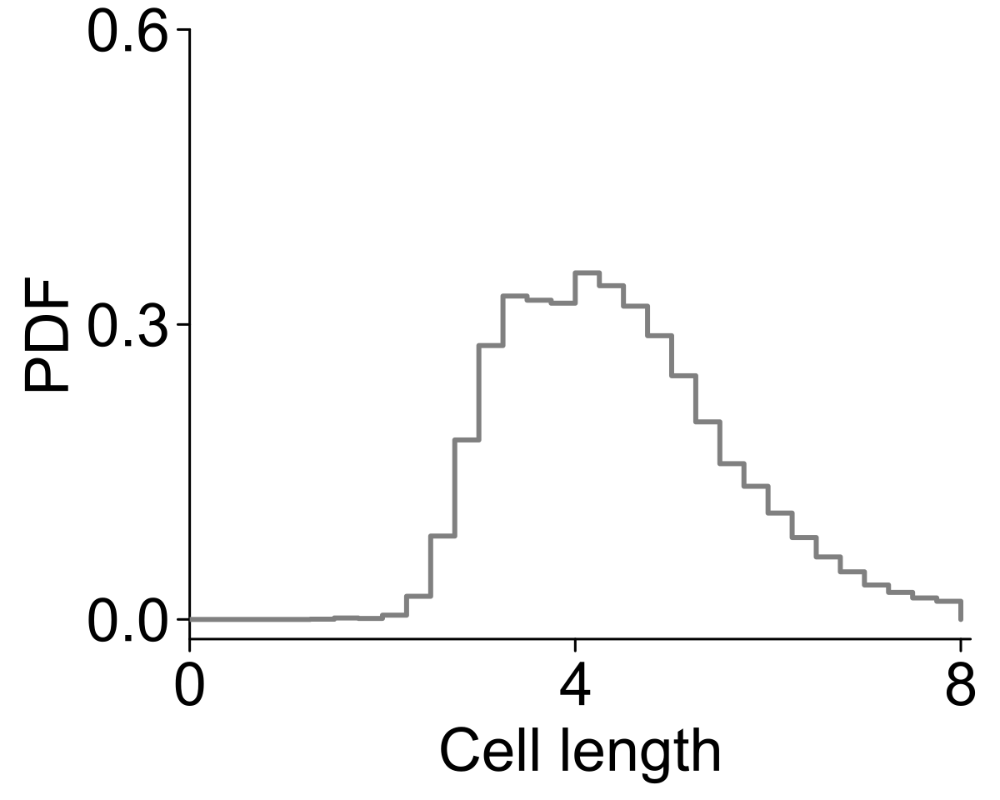

In [7]:
p1 = plot(;xlim=(0,8.1), xtick=[0,4,8],ylim=(-0.02,0.6),ytick=[0,0.3,0.6])
stephist!( p1, vcat(Lobs_...), bins=collect(0:0.25:8), normalize=:pdf, xlabel="Cell length", ylabel="PDF")


### Joint Porbability

In [8]:
using StatsBase
hedges = collect(3:0.35:10.0);
hbins = 0.5*( hedges[1:end-1] + hedges[2:end] )
dhedges = mean( diff(hedges) );

h1_obs = fit(Histogram, vcat( [Lobs_[i][isdiv_[i]] for i in eachindex(Lobs_) ]...), hedges)
h2_obs = fit(Histogram, (vcat( [Lobs_[i][isdiv_[i]][1:end-1] for i in eachindex(Lobs_) ]...), vcat( [Lobs_[i][isdiv_[i]][2:end] for i in eachindex(Lobs_) ]...) ), (hedges,hedges));

 

Histogram{Int64, 2, Tuple{Vector{Float64}, Vector{Float64}}}
edges:
  [3.0, 3.35, 3.7, 4.05, 4.4, 4.75, 5.1, 5.45, 5.8, 6.15  …  6.85, 7.2, 7.55, 7.9, 8.25, 8.6, 8.95, 9.3, 9.65, 10.0]
  [3.0, 3.35, 3.7, 4.05, 4.4, 4.75, 5.1, 5.45, 5.8, 6.15  …  6.85, 7.2, 7.55, 7.9, 8.25, 8.6, 8.95, 9.3, 9.65, 10.0]
weights: [0 0 … 0 0; 0 0 … 0 0; … ; 0 0 … 5 3; 0 0 … 2 3]
closed: left
isdensity: false

In [9]:
# obs
h1_obs_normalize = h1_obs.weights / sum(h1_obs.weights) / dhedges
h2_obs_normalize = h2_obs.weights / sum(h2_obs.weights) / dhedges^2

svd_h1_obs = svd(h1_obs_normalize * h1_obs_normalize');
svd_h2_obs = svd(h2_obs_normalize);

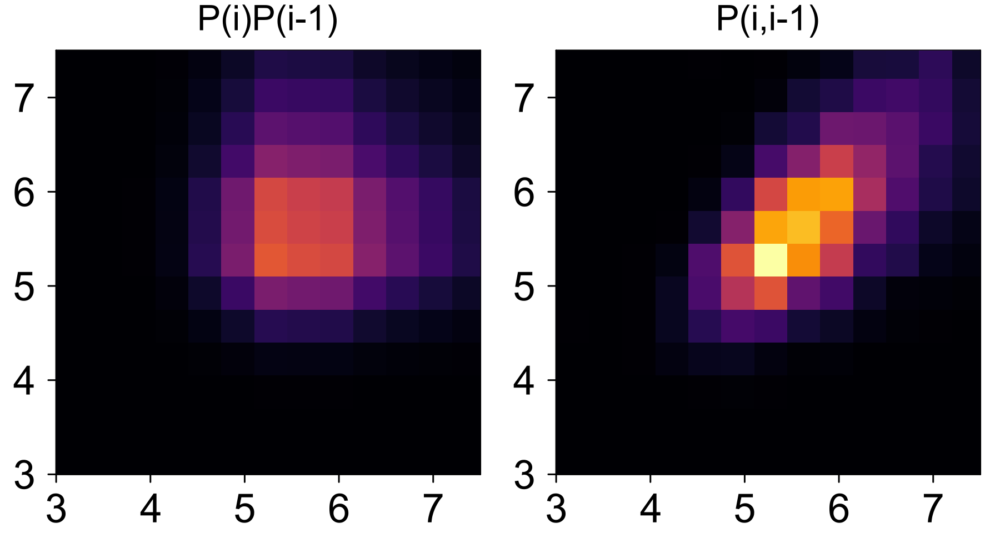

In [10]:
p_h1_obs = plot(; aspect_ratio=1, framestyle=:box, xlim=(3,7.5), ylim=(3,7.5), xtick=collect(3:8), ytick=collect(3:8), title="P(i)P(i-1)" )
heatmap!( p_h1_obs, hbins, hbins, h1_obs_normalize * h1_obs_normalize', clim=(0,0.4)) 

p_h2_obs = plot(; aspect_ratio=1, framestyle=:box, xlim=(3,7.5), ylim=(3,7.5), xtick=collect(3:8), ytick=collect(3:8), title="P(i,i-1)" )
heatmap!( p_h2_obs, hbins, hbins, h2_obs_normalize, clim=(0,0.4)) 

ll = @layout [a b]
plot(p_h1_obs, p_h2_obs, layout = ll, size=(600,320))

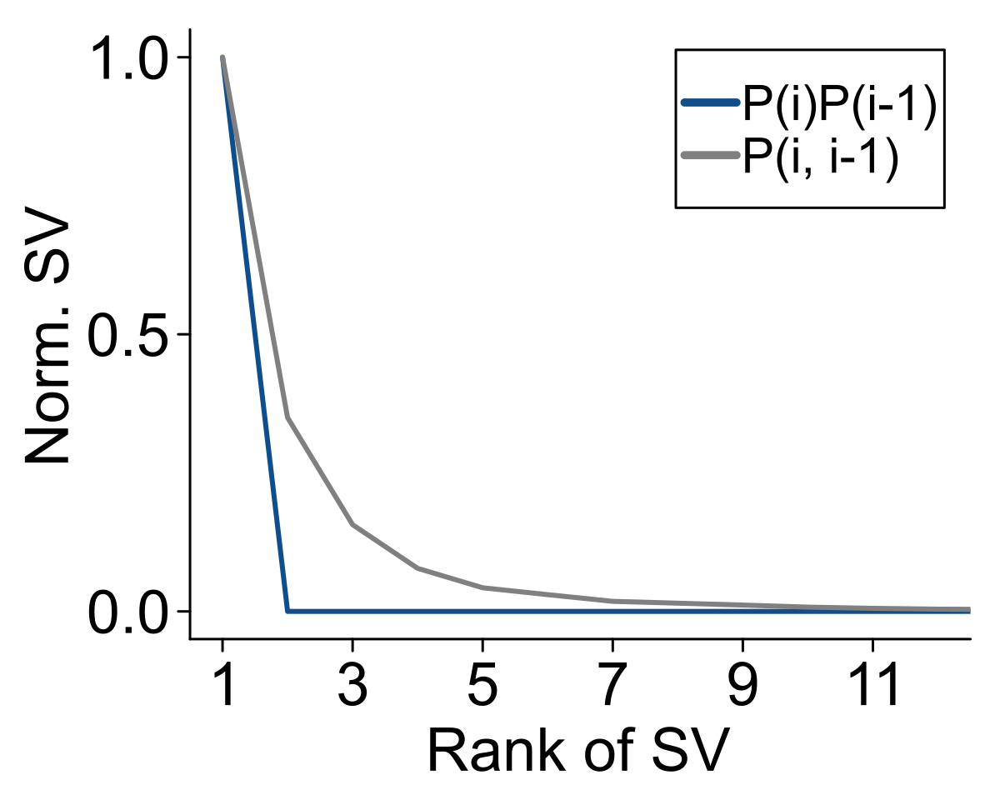

In [11]:
p_S_obs = plot(; xlim=[0.5,12.5], ylim=[-0.05,1.05], ytick=[0,0.5,1], xtick=collect(1:2:13), xlabel="Rank of SV", ylabel = "Norm. SV", legend=true)
plot!( p_S_obs, svd_h1_obs.S ./ svd_h1_obs.S[1], lc=:dodgerblue4, label="P(i)P(i-1)" )
plot!( p_S_obs, svd_h2_obs.S ./ svd_h2_obs.S[1],  label="P(i, i-1)" )

In [14]:
function plot_histogram!( pp, _hedges::Vector{T}, _y::Vector{T}; plot_args...) where T
    _index_edges = vcat([[i,i] for i in 1:length(_hedges)]...);
    _index_y = vcat([[i,i] for i in 1:length(_y)]...);
    plot!(pp, _hedges[_index_edges[2:end-1]], _y[_index_y]; plot_args...)
    nothing
end

plot_histogram! (generic function with 1 method)

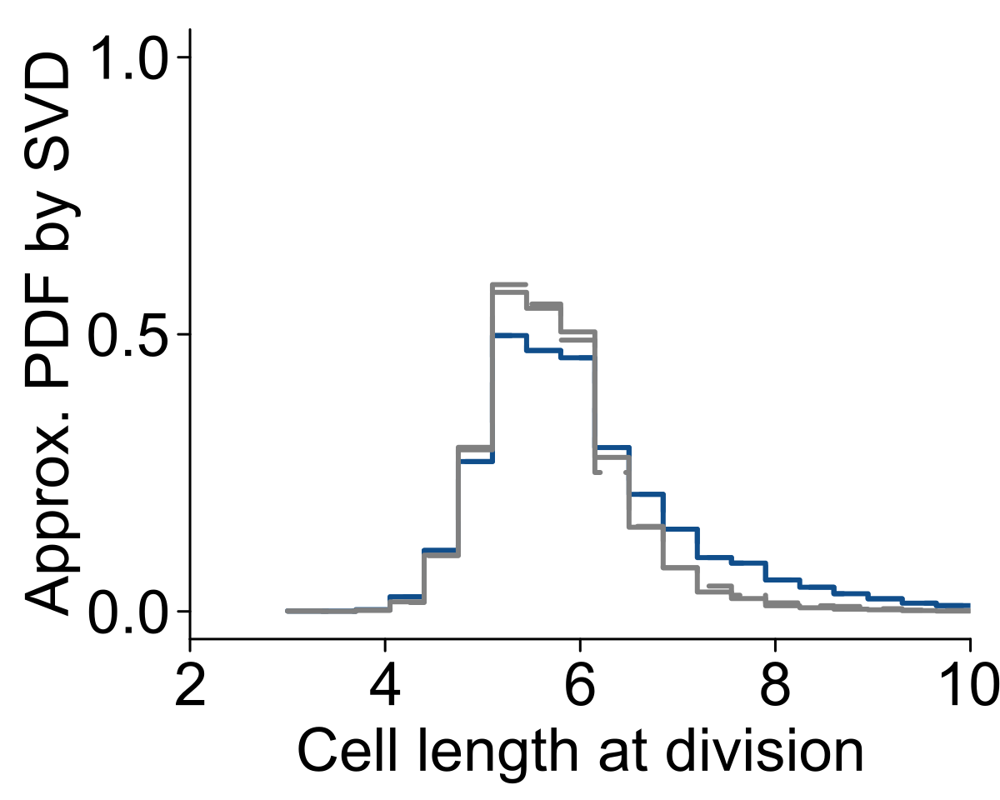

In [16]:
yU_h1_obs = svd_h1_obs.U[:,1] * sqrt(svd_h1_obs.S[1])
yV_h1_obs = svd_h1_obs.V[:,1] * sqrt(svd_h1_obs.S[1])

yU_h2_obs = svd_h2_obs.U[:,1] * sqrt(svd_h2_obs.S[1])
yV_h2_obs = svd_h2_obs.V[:,1] * sqrt(svd_h2_obs.S[1])

p_UV_obs = plot(; ylim=(-0.05,1.05), xlim=(2,10), xtick=collect(2:2:10), ytick=collect(0:0.5:1), xlabel="Cell length at division", ylabel="Approx. PDF by SVD")
plot_histogram!(p_UV_obs, hedges, abs.(yU_h1_obs); lc=:dodgerblue4)
plot_histogram!(p_UV_obs, hedges, abs.(yV_h1_obs); ls=:dash, lc=:dodgerblue4)
plot_histogram!(p_UV_obs, hedges, abs.(yU_h2_obs))
plot_histogram!(p_UV_obs, hedges, abs.(yV_h2_obs); ls=:dash)
p_UV_obs